In [5]:
from ultralytics import YOLO
import os ,cv2
import numpy as np 
import matplotlib.pyplot as plt

In [6]:
## MODEL LOADING :  in 'contents' of sheet 
model =  YOLO("flower_model.pt")  


##  for prediction purpose 
class_names = model.names
color_dict = {
    "blue" : (255,0,0),
    "red": (0,0,255),
    "green": (0,255,0),
    "pink": (203,192,255),
    "cyan":(255,255,0)
}

**Now comes Model interference part  or in simple terms prediction from trained model: **
>mentioned in 'contents'  of sheet
-  for single image
-  for whole folder 

**Code for detecting single image only !**

In [7]:
values =  [val for key,val in model.names.items()]
for i in values :
    print(i)

Lilly
Lotus
Orchid
Sunflower
Tulip


In [10]:

def detect_flower_image(image_path, rect_color="red", text_Color="blue", to_rgb=True):
    
    sample_img = cv2.imread(image_path)

    # Run prediction using the model
    results = model.predict(image_path)  # result produced by YOLO model 
    length_objs = len(results[0].boxes)  # all imp data stored in results[0].boxes
    classes = {}
    
    ## Now just draw the boxes , detect no of classes and total objects detected

    for i, box in enumerate(results[0].boxes):
        cls = int(box.cls.item())
        class_name = class_names[cls]
        conf = float(box.conf.item()) * 100

        classes[f"{class_name}_{i}"] = f"{conf:.2f}%"

        x1, y1, x2, y2 = map(int, box.xyxy[0]) # coordinates of the bounding box
        cv2.rectangle(sample_img, (x1, y1), (x2, y2), color_dict[rect_color], 2)

        text_y = max(y1 - 10, 10)
        cv2.putText(sample_img, f"{class_name} {conf:.2f}%", (x1, text_y),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, color_dict[text_Color], 2)

    if to_rgb:
        sample_img = cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB)

    return sample_img, classes, length_objs



image 1/1 c:\codes\Lab\flower_fiv_yolo\sample_images\flower_1.jpg: 640x640 1 Orchid, 74.8ms
Speed: 2.2ms preprocess, 74.8ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 640)
Results saved to C:\codes\Lab\flower_fiv_yolo\runs\detect\predict
12 labels saved to C:\codes\Lab\flower_fiv_yolo\runs\detect\predict\labels
Total objects detected: 1
Classes detected: {'Orchid_0': '82.58%'}


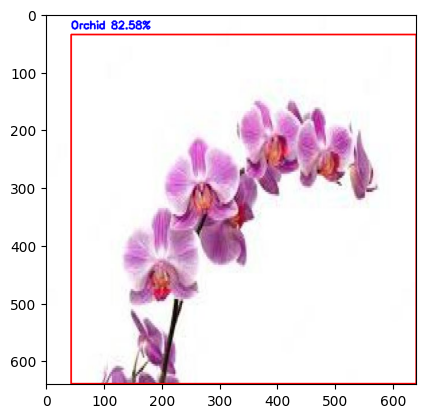

In [13]:
detected_image , classes,length_objs = detect_food_image("sample_images/flower_1.jpg")

print(f"Total objects detected: {length_objs}")
print("Classes detected:", classes)
plt.imshow(detected_image)

**code for detecting whole folder of images like 'sample_images' !**

In [11]:
# Results saved to runs\detect\

for i in os.listdir("sample_images") :
    if i.endswith(".jpg") or i.endswith(".png"):
        results = model.predict(source=f"sample_images/{i}", save=True, save_txt=True, save_conf=True)
        print(f"Processed {i}: {results}")




image 1/1 c:\codes\Lab\flower_fiv_yolo\sample_images\flower_1.jpg: 640x640 1 Orchid, 93.3ms
Speed: 2.7ms preprocess, 93.3ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)
Results saved to C:\codes\Lab\flower_fiv_yolo\runs\detect\predict
1 label saved to C:\codes\Lab\flower_fiv_yolo\runs\detect\predict\labels
Processed flower_1.jpg: [ultralytics.engine.results.Results object with attributes:

boxes: ultralytics.engine.results.Boxes object
keypoints: None
masks: None
names: {0: 'Lilly', 1: 'Lotus', 2: 'Orchid', 3: 'Sunflower', 4: 'Tulip'}
obb: None
orig_img: array([[[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,


In [12]:
print("ALL THE PREDICTED IMAGES SAVED IN : ",results[0].save_dir)

ALL THE PREDICTED IMAGES SAVED IN :  C:\codes\Lab\flower_fiv_yolo\runs\detect\predict
